# SDialog Tutorial: Testing Agents with Simulated Users

<p align="right" style="margin-right: 8px;">
    <a target="_blank" href="https://colab.research.google.com/github/idiap/sdialog/blob/main/tutorials/agents/4.testing_with_simulated_users.ipynb">
        <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
    </a>
</p>

Before letting real users talk to an agent, we want to know how it behaves: does it follow its rules, call the right tools, stay polite with difficult users? Testing it by hand covers a few conversations at best. With SDialog, **simulated users** (agents with their own personas and goals) can talk to it as many times as we want, and the resulting dialogues can be checked automatically.

What you will learn:
- Generate a variety of simulated users from a persona
- Let them talk to the agent under test
- Check the dialogues with rule-based checks (tool calls) and LLM judges
- Compare two versions of an agent

## 1. Setup

In [1]:
# Setup the environment depending on whether we are running in Google Colab or Jupyter Notebook
from IPython import get_ipython


if "google.colab" in str(get_ipython()):
    print("Running on CoLab")

    # Installing Ollama (if you are not planning to use Ollama, you can just comment these lines to speed up the installation)
    !apt-get install zstd
    !curl -fsSL https://ollama.com/install.sh | sh

    # Installing sdialog
    !git clone https://github.com/idiap/sdialog.git
    %cd sdialog
    %pip install -e .
    %cd ..
else:
    print("Running in Jupyter Notebook")
    # Little hack to avoid the "OSError: Background processes not supported." error in Jupyter notebooks"
    import os
    get_ipython().system = os.system

Running in Jupyter Notebook


If you plan to use an Ollama backend locally, start the server in the background. If you use OpenAI/Bedrock/HF instead, you can skip this cell.

In [2]:
# Let's run the ollama server in the background
!OLLAMA_KEEP_ALIVE=-1 ollama serve > /dev/null 2>&1 &
!sleep 5

Set the global model used by SDialog (any "BACKEND:MODEL" string works, e.g. `"openai:gpt-4.1"`). It is used by the agent under test, the simulated users and the LLM judge, but each can use its own model (`model=` argument):

In [3]:
import sdialog

sdialog.config.llm("ollama:qwen3:14b")
# sdialog.config.llm("openai:gpt-4.1")  # e.g. OpenAI GPT-4.1 (set the OPENAI_API_KEY environment variable)

## 2. The agent under test

A call center agent of a telecom company, with three tools. Our policy: **the customer's account must be verified before changing any account data** (e.g. the billing address).

We build two versions of the agent, one without the policy in its rules and one with it, to see whether adding it actually changes the agent's behavior:

In [4]:
from sdialog.agents import Agent
from sdialog.personas import SupportAgent


def verify_account(customer_id: str) -> dict:
    """Verify a customer's account by its customer id."""
    return {"customer_id": customer_id, "verified": True}


def update_billing_address(customer_id: str, new_address: str) -> dict:
    """Update the billing address of a customer's account."""
    return {"customer_id": customer_id, "address_updated": True}


def get_service_plans() -> dict:
    """Get the available service plans and their prices."""
    return {"plans": [{"name": "Basic", "price": "$29.99/month"}, {"name": "Premium", "price": "$49.99/month"}]}


def build_support_agent(rules: str = "") -> Agent:
    persona = SupportAgent(name="Michael", politeness="high", rules=rules)
    return Agent(persona, tools=[verify_account, update_billing_address, get_service_plans],
                 first_utterance="Hello, this is Michael from Synergy Communications. How can I help you?",
                 name="Support")


agents = {
    "v1 (no policy)": build_support_agent(),
    "v2 (with policy)": build_support_agent(rules="Always verify the customer's account (verify_account tool) "
                                                  "before changing any account data."),
}

## 3. Simulated users

Our simulated users are customers who want to update their billing address. Instead of writing each of them by hand, we let `PersonaGenerator` create varied customers from a base persona: here we choose their politeness at random from a list, and let the LLM fill in the rest of each persona (name, age, personality, ...):

In [5]:
from sdialog.personas import Customer
from sdialog.generators import PersonaGenerator

customer_generator = PersonaGenerator(Customer(issue="Need to update the billing address of my account"))
customer_generator.set(politeness=["rude", "neutral", "very polite"])

customers = customer_generator.generate(n=5)
customers[0].print()

[version] 0.8.0
[timestamp] 2026-11-04T09:24:52Z
[model] {'name': 'ollama:qwen3:14b', 'seed': 3230135078, 'top_p': 0.95, 'repeat_penalty': 1, 'temperature': 0.6, 'top_k': 20}
[seed] 3230135078
[id] 791c74e7-ddfa-41ee-9efb-faa72bf16b30
[className] Customer
--- Customer Begins ---
[Name] Emily Carter
[Age] 34
[Gender] female
[Language] English
[Customer id] CUST-1001
[Occupation] Marketing Manager
[Account tenure] 3 years
[Membership level] Gold
[Loyalty status] loyal
[Fidelity score] 85
[Issue] Need to update the billing address of my account
[Issue category] billing
[Issue description] I recently moved and need to update my billing address to ensure payments are processed correctly.
[Issue history] No prior issues related to billing.
[Desired outcome] Update billing address successfully without any delays.
[Knowledge domain] Basic understanding of account management
[Technical expertise] Low
[Sentiment] neutral
[Anger level] low
[Tiredness] moderate
[Patience level] high
[Politeness] r

## 4. Simulated conversations

Each simulated customer talks to each version of the agent. `talk_with()` returns the dialogue, including the **events**: the agent's tool calls and their results:

In [6]:
from tqdm.auto import tqdm

dialogs = {version: [] for version in agents}
for version, support in agents.items():
    for customer in tqdm(customers, desc=version):
        dialogs[version].append(support.talk_with(Agent(customer, name="Customer"), max_turns=12))

dialogs["v1 (no policy)"][0].print(all=True)  # all=True also shows the events (tool calls, results, ...)

[dialog_id] 7e8cad1f-5e0e-48a3-a14f-8d66e1eccccc
[complete] True
[model] {'name': 'ollama:qwen3:14b', 'seed': 13, 'top_p': 0.95, 'repeat_penalty': 1, 'temperature': 0.6, 'top_k': 20}
[seed] 4086662628
--- Dialogue Begins ---
[Support] Hello, this is Michael from Synergy Communications. How can I help you?
[Customer] I need to update my billing address. Can we get that done quickly?
[Support] Sure, I can help with that. Could you please provide your customer ID and the new billing address?
[Customer] CUST-1001. The new address is 123 Maple Street, Springfield, IL, 62704.
[tool-call] (Support) {'name': 'update_billing_address', 'args': {'customer_id': 'CUST-1001', 'new_address': '123 Maple Street, Springfield, IL, 62704'}, 'id': 'ac03fe99-6223-48f8-8526-12075246f939'}
[tool-output] {'name': 'update_billing_address', 'output': '{"customer_id": "CUST-1001", "address_updated": true}', 'call_id': 'ac03fe99-6223-48f8-8526-12075246f939'}
[Support] Your billing address has been successfully upd

## 5. Checking a dialogue

Two kinds of checks, which can be combined:

- **Rule-based**, for what can be checked exactly. `ToolSequenceValidator` checks the agent's tool calls: here, that the account was verified before the address was updated (1 if so, 0 otherwise).
- **LLM judges**, for what needs understanding. `LLMJudgeYesNo` asks an LLM a yes/no question about the dialogue (here, the customer is rude in some dialogues: did the agent stay polite?).

In [7]:
from sdialog.evaluation import ToolSequenceValidator, LLMJudgeYesNo

verified_before_update = ToolSequenceValidator(["verify_account", "update_billing_address"])
stayed_polite = LLMJudgeYesNo("Did the support agent stay polite and professional during the whole dialogue?",
                              reason=True)

dialog = dialogs["v1 (no policy)"][0]
print("Verified before update:", verified_before_update(dialog))
result = stayed_polite.judge(dialog)
print("Stayed polite:", result.positive, "-", result.reason)

Verified before update: 0
Stayed polite: True - The support agent maintained a polite and professional tone throughout the conversation, using appropriate language, being helpful, and ensuring a smooth resolution to the customer's request.


## 6. Comparing the two versions

To check all the dialogues at once, `FrequencyEvaluator` turns each check into the percentage of dialogues that pass it, and `Comparator` computes these for each version of the agent:

In [8]:
from sdialog.evaluation import Comparator, FrequencyEvaluator

comparator = Comparator(evaluators=[
    FrequencyEvaluator(verified_before_update, name="Verified before update"),
    FrequencyEvaluator(stayed_polite, name="Stayed polite"),
])
comparator(dialogs)

| dataset          |   Verified before update |   Stayed polite |
|:-----------------|-------------------------:|----------------:|
| v1 (no policy)   |                     0.00 |            1.00 |
| v2 (with policy) |                     1.00 |            1.00 |


{'v1 (no policy)': {'Verified before update': np.float64(0.0),
  'Stayed polite': np.float64(1.0)},
 'v2 (with policy)': {'Verified before update': np.float64(1.0),
  'Stayed polite': np.float64(1.0)}}

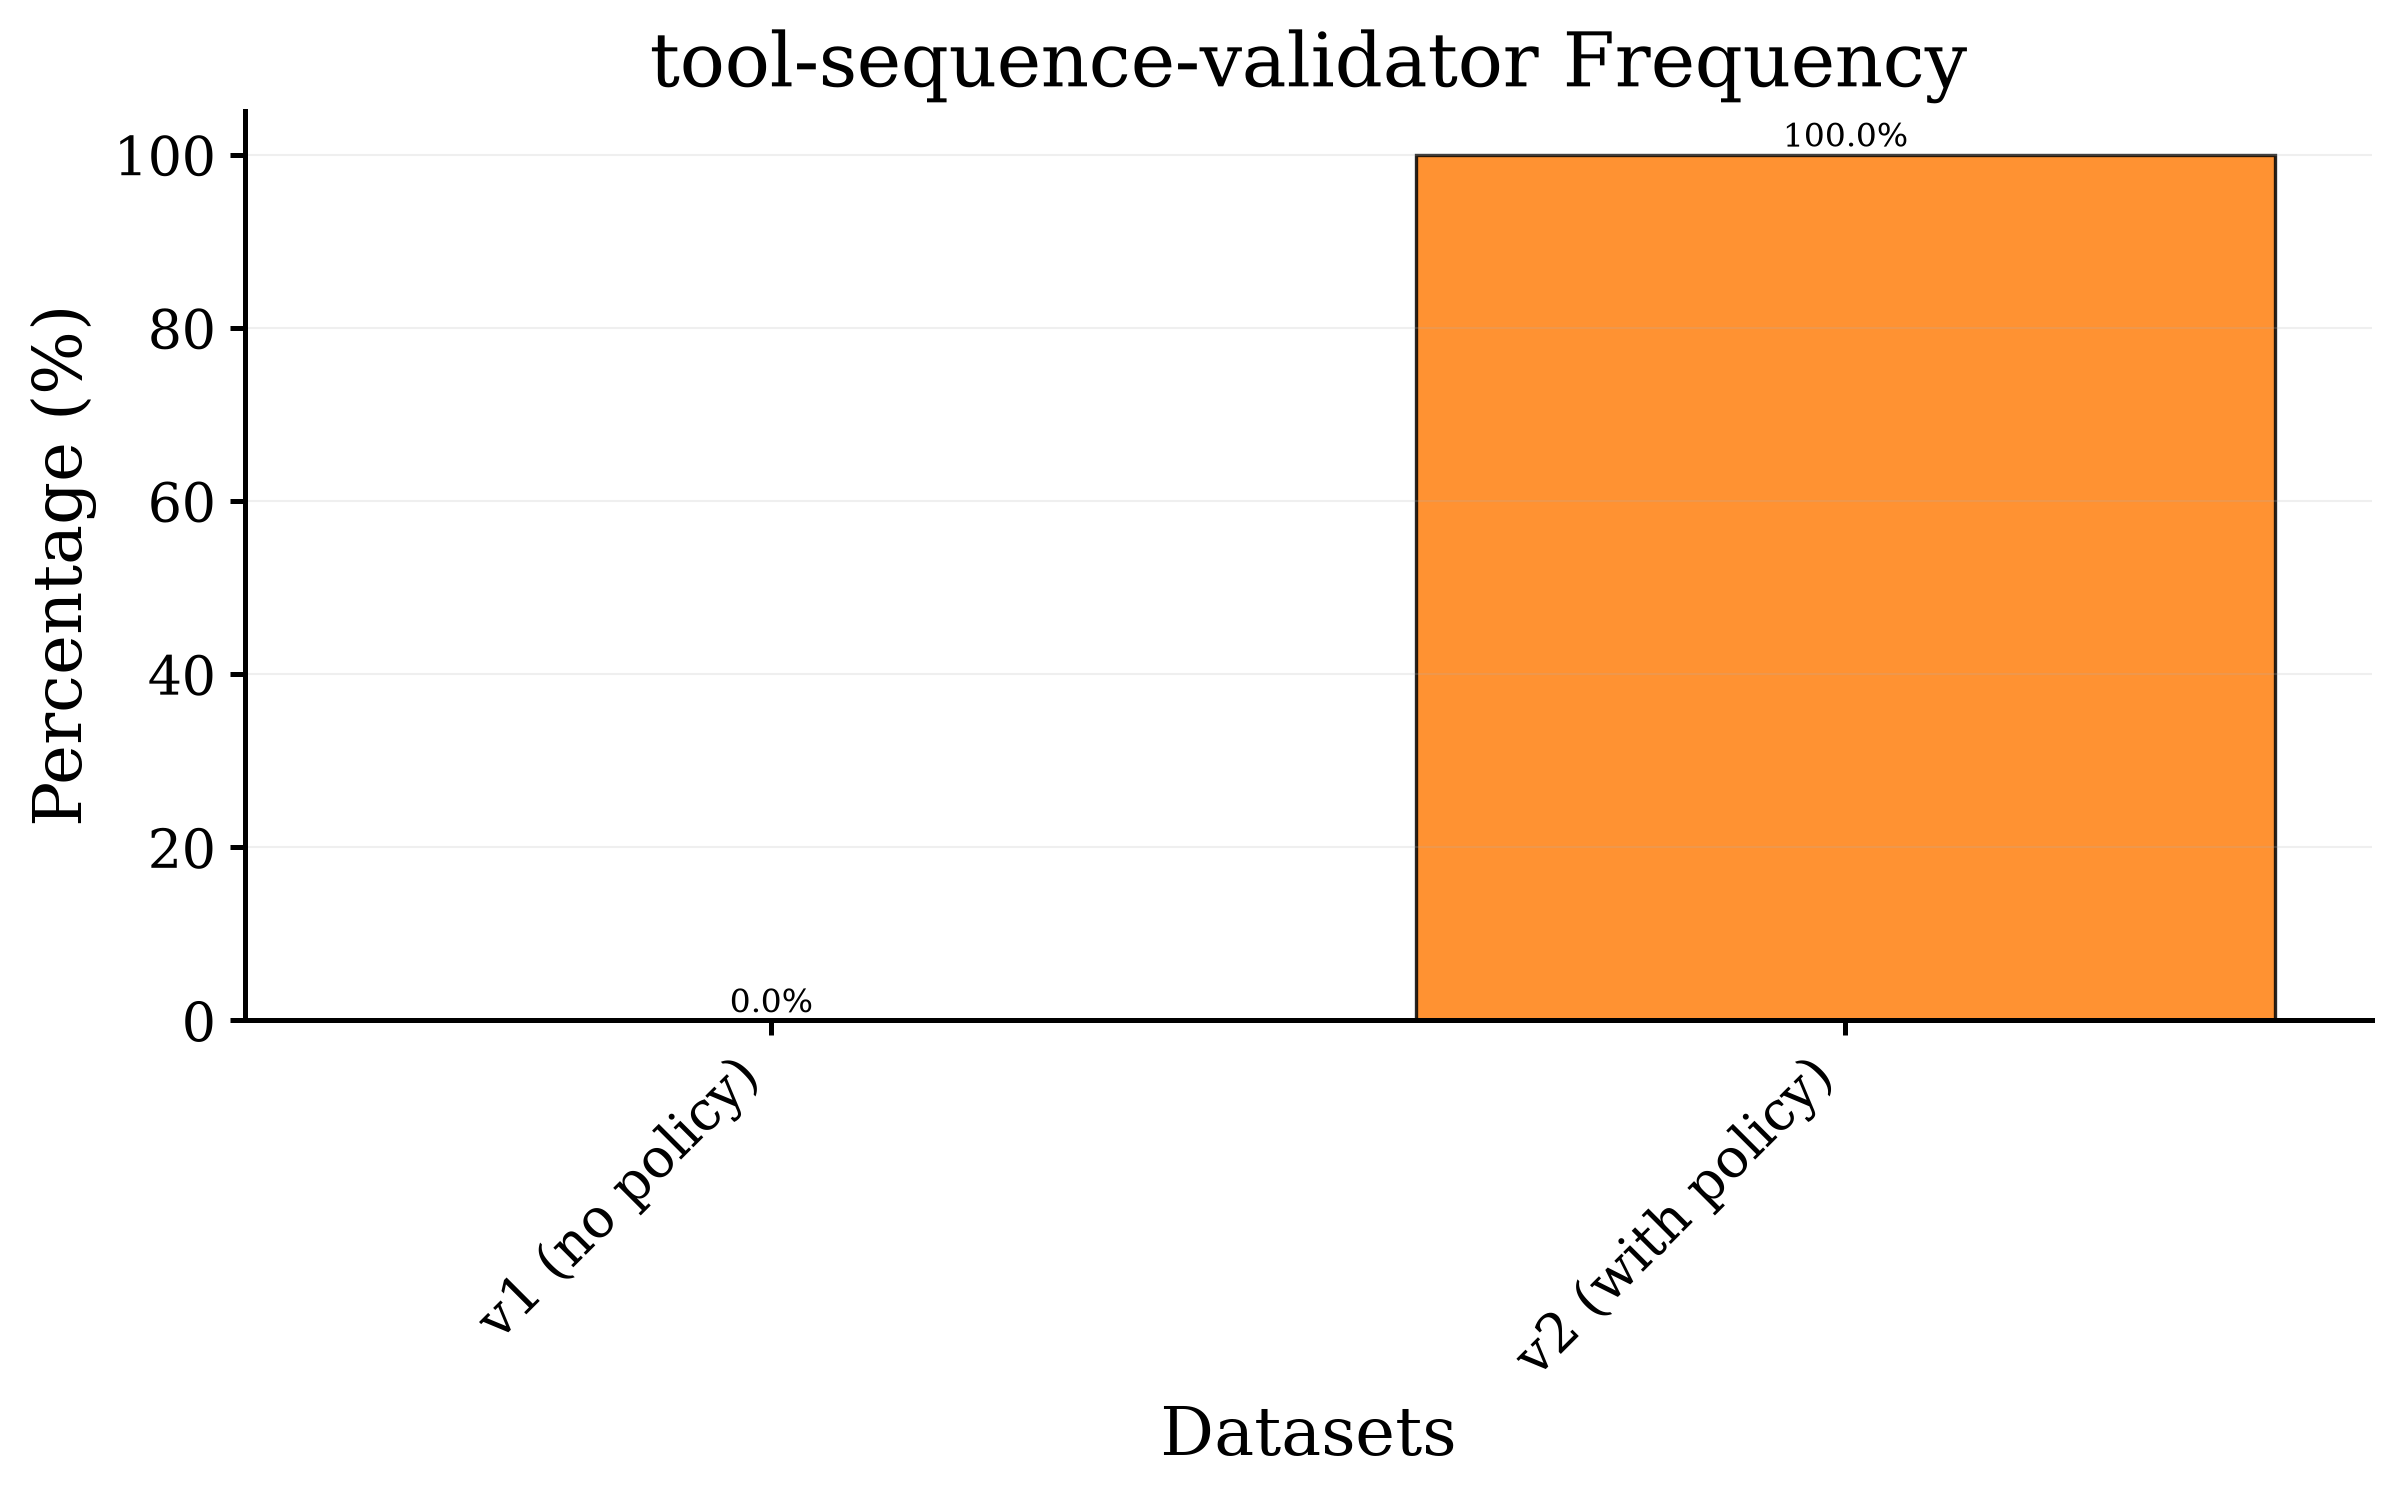

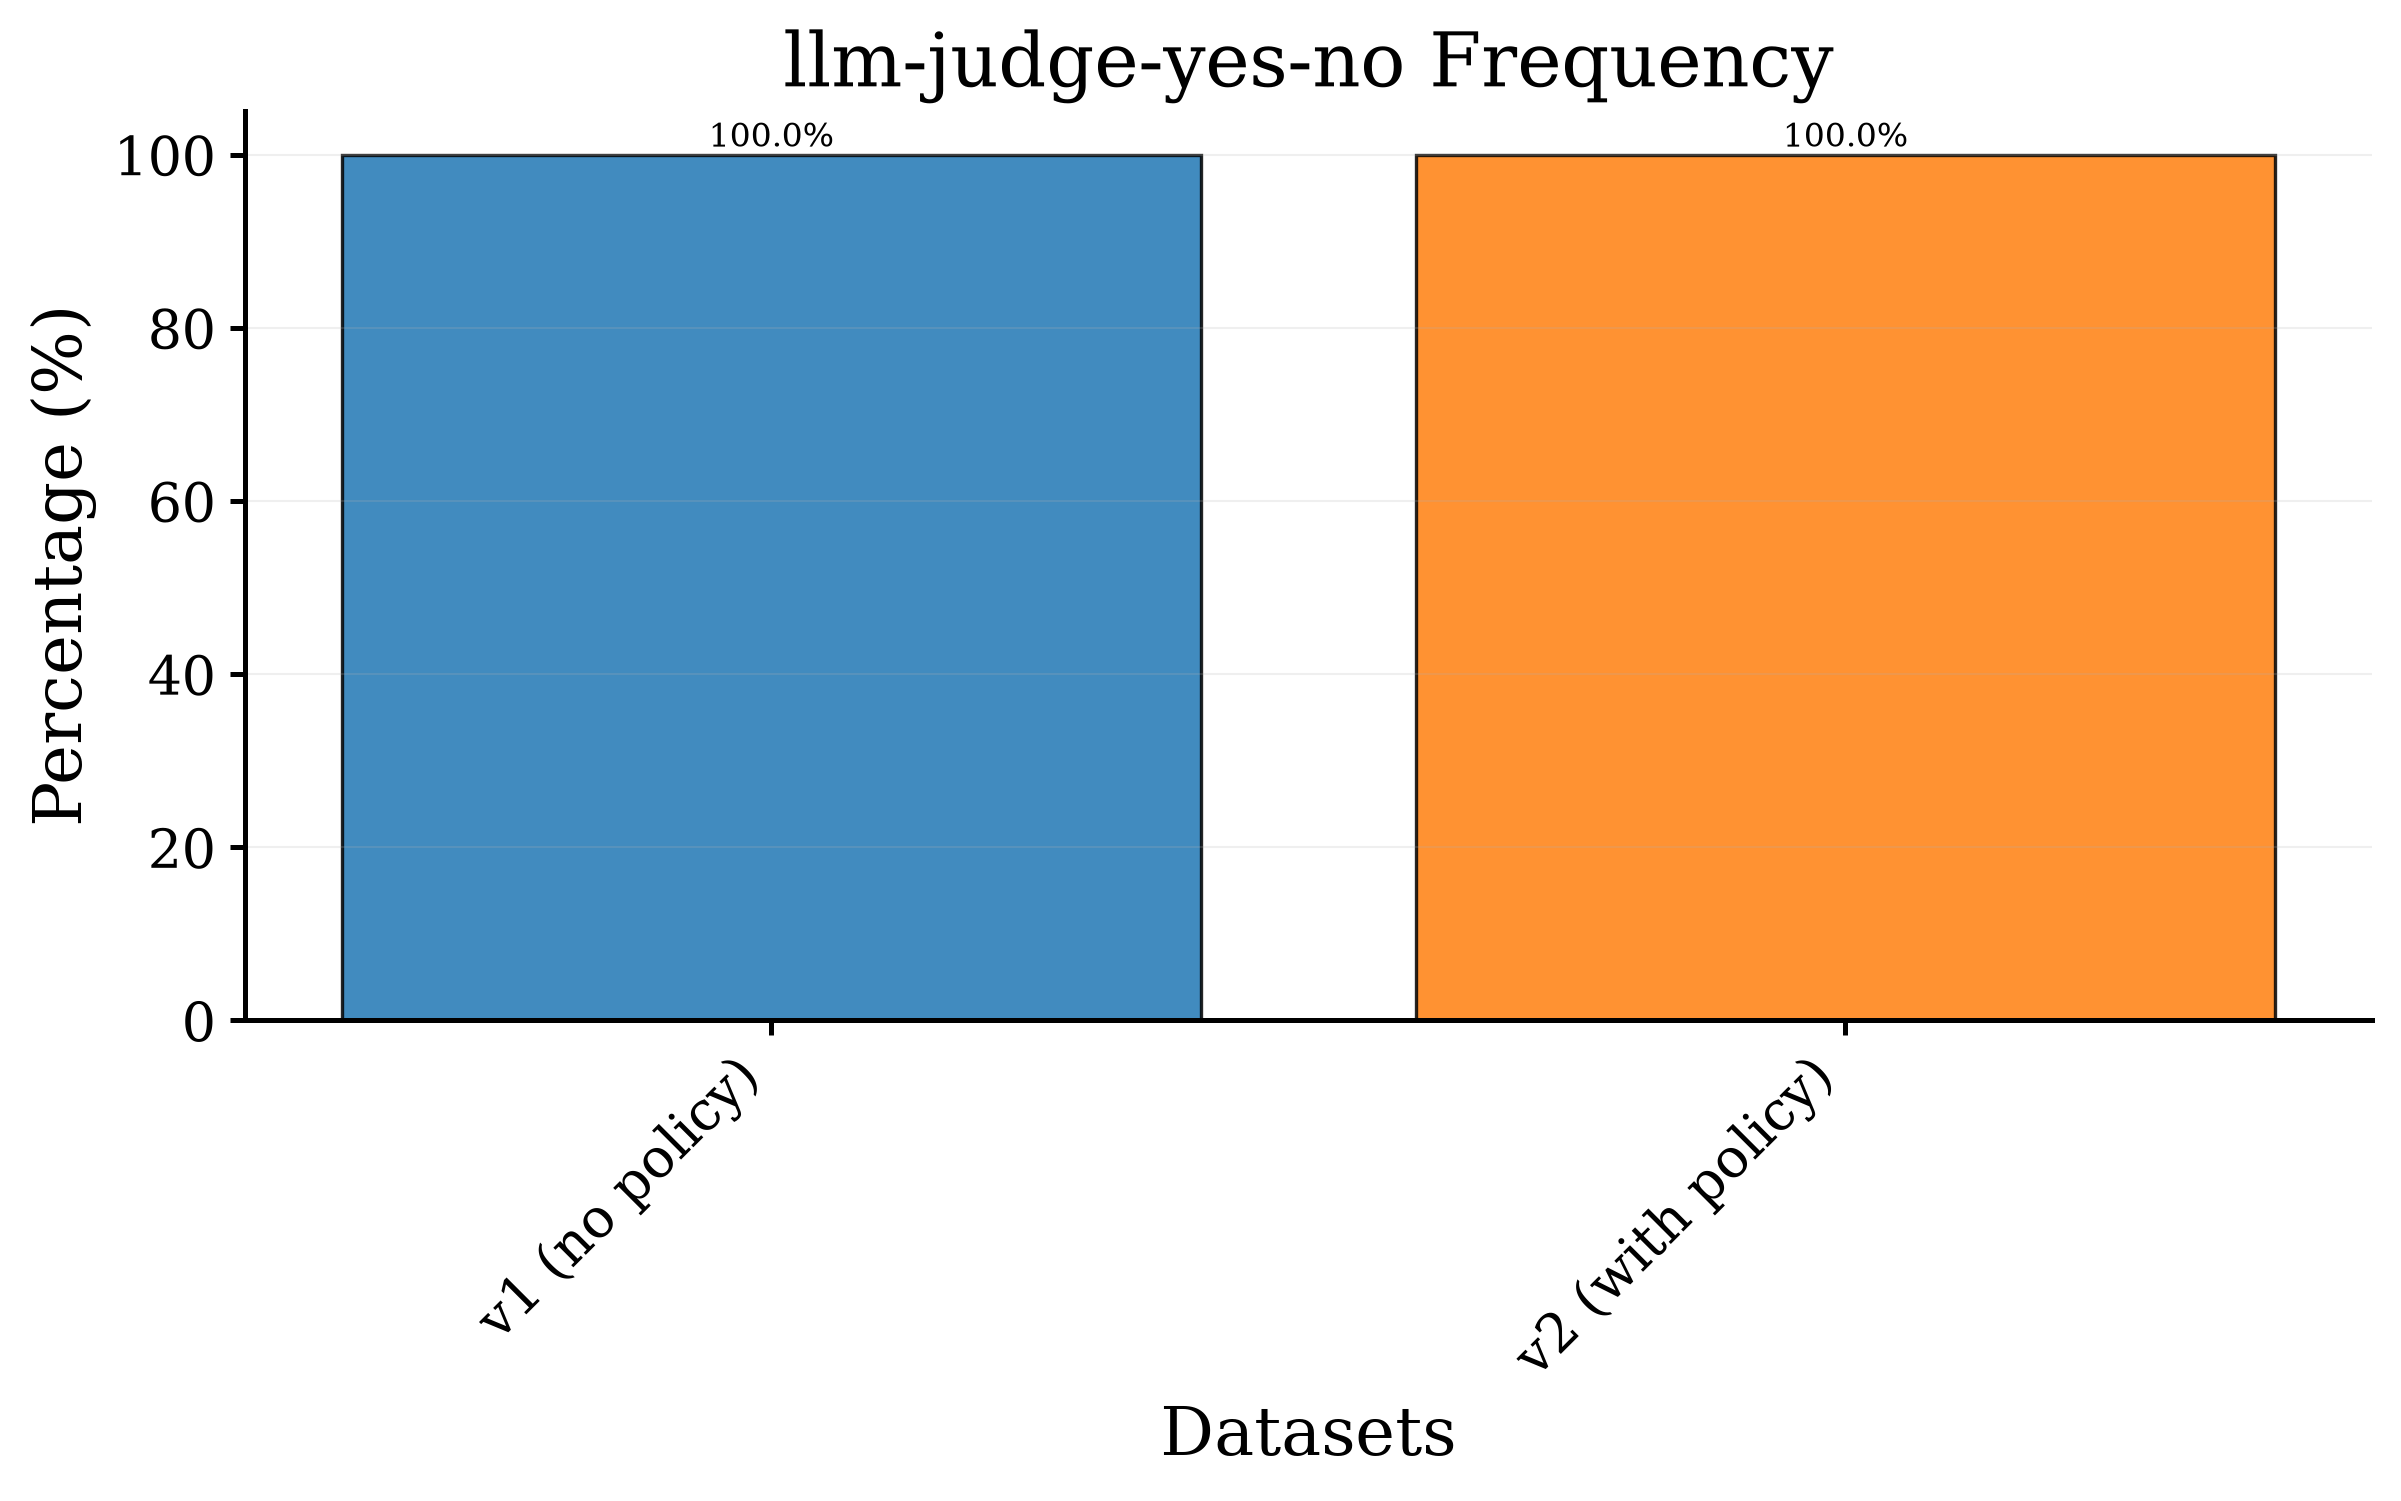

In [9]:
comparator.plot()

With only five customers, these percentages are rough estimates: with more simulated users (e.g. 50 or 100), and different issues, the comparison becomes reliable, and you can keep the same users to compare every new version of your agent (its prompt, rules, tools or model), as a regression test.

> 💡 More checks:
> - `ToolSequenceValidator(["not:verify_account", "get_service_plans"])` checks that the agent did **not** verify the account before listing the plans (e.g. for customers who only ask about prices), and `forbidden_tools=[...]` that some tools are never called.
> - Other LLM judges (`LLMJudgeScore`, ...) and metrics are listed in the [evaluation documentation](https://sdialog.readthedocs.io/en/latest/sdialog/index.html#evaluation-suite).
> - The agent under test does not need to be built with SDialog: wrap any deployed OpenAI-compatible system as an `Agent` (see [testing remote systems with simulated users](https://github.com/idiap/sdialog#-testing-remote-systems-with-simulated-users)).

Finally, let's save the dialogues to inspect them later:

In [10]:
import os

for version, version_dialogs in dialogs.items():
    folder = f"output/testing/{version.split()[0]}"
    os.makedirs(folder, exist_ok=True)
    for ix, dialog in enumerate(version_dialogs):
        dialog.to_file(f"{folder}/dialog_{ix}.json")